# CardioFusion-XAI — PTB-XL ECG explainability

This notebook calculates Integrated Gradients for a real PTB-XL test waveform using the trained ECG expert. Attribution is grouped by lead and time index to avoid a visually overwhelming 12,000-value explanation.

The explanation depends on the selected zero-waveform baseline and is not anatomical localization, a causal explanation or an independent clinical interpretation.

In [1]:
from pathlib import Path
import os
import sys


def find_ml_service_root(start=None):
    current = Path(start or Path.cwd()).resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "pyproject.toml").is_file() and (candidate / "src").is_dir() and (candidate / "config").is_dir():
            return candidate
    raise FileNotFoundError(
        "Could not locate ml-service/. Start Jupyter from the repository or from ml-service/."
    )


ML_ROOT = find_ml_service_root()
os.chdir(ML_ROOT)
if str(ML_ROOT) not in sys.path:
    sys.path.insert(0, str(ML_ROOT))
print(f"ML project root: {ML_ROOT}")

ML project root: D:\Programming\VS Code\Projects\CardioFusion-XAI\ml-service


## 1. Load the trained ECG model and patient-disjoint test loader

In [2]:
import numpy as np
import torch
from src.inference.model_manager import ModelManager
from src.datasets.ptbxl_loader import build_ptbxl_loaders
from src.xai.explanation_service import ExplanationService

models = ModelManager(ML_ROOT)
if models.ecg_model is None:
    raise FileNotFoundError("ECG checkpoint is missing. Train the ECG expert before running explainability.")
loaders = build_ptbxl_loaders(
    data_root=ML_ROOT,
    batch_size=1,
    seed=42,
    preprocessing_version="100hz_record_zscore",
    num_workers=0,
    pin_memory=False,
)
batch = next(iter(loaders["test"]))
waveform = batch["signal"][0].detach().cpu().numpy().astype(np.float32)
print("Waveform shape:", waveform.shape)
print("Diagnostic targets:", models.ecg_diagnostic_targets)

Waveform shape: (12, 1000)
Diagnostic targets: ['NORM', 'MI', 'STTC', 'CD', 'HYP']


## 2. Select an output and calculate Integrated Gradients

The output is selected by the highest inference probability (calibrated where a matching calibration artifact exists). Integrated Gradients attributes the selected model head's logit relative to a zero-waveform baseline; the attribution is not a gradient of calibrated probability. This is a demonstration, not a thresholded diagnosis. For a research experiment, pre-register the label of interest and aggregate explanations over an independent test cohort.

In [3]:
from src.xai.ecg_explainer import integrated_gradients_ecg

scores = models.predict_ecg(waveform)
# predict_ecg returns scalar probabilities keyed by output label, plus *_raw and _metadata entries.
target_names = [*models.ecg_diagnostic_targets, *models.ecg_rhythm_targets]
target_scores = {
    name.removeprefix("RHYTHM_"): float(scores[name.removeprefix("RHYTHM_")])
    for name in target_names
    if name.removeprefix("RHYTHM_") in scores
}
if not target_scores:
    raise RuntimeError("The ECG model returned no scores matching its target manifest.")
if not np.isfinite(list(target_scores.values())).all():
    raise ValueError("The ECG model returned a non-finite target probability.")
ranked = sorted(target_scores.items(), key=lambda item: item[1], reverse=True)
label, probability = ranked[0]
lookup = {name: ("diagnostic", index) for index, name in enumerate(models.ecg_diagnostic_targets)}
lookup.update({name.removeprefix("RHYTHM_"): ("rhythm", index) for index, name in enumerate(models.ecg_rhythm_targets)})
if label not in lookup:
    raise KeyError(f"Selected target {label!r} is not in the checkpoint target manifest.")
task, target_index = lookup[label]
explanation = integrated_gradients_ecg(models.ecg_model, waveform, target_index, task=task, device=models.device)
print("Selected output:", label)
print("Inference probability:", probability)
print("Probability metadata:", scores.get("_metadata", {}).get("targets", {}).get(label, {}))
print("Attribution target: raw model-head logit")
print("Method:", explanation["method"])

Selected output: NORM
Inference probability: 0.9420526292730965
Probability metadata: {'calibrated': True, 'calibration_method': 'platt'}
Attribution target: raw model-head logit
Method: IntegratedGradients


## 3. Plot lead and temporal importance

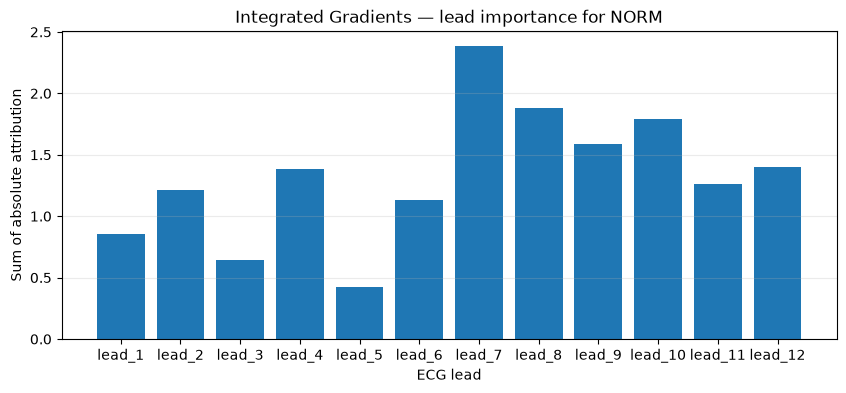

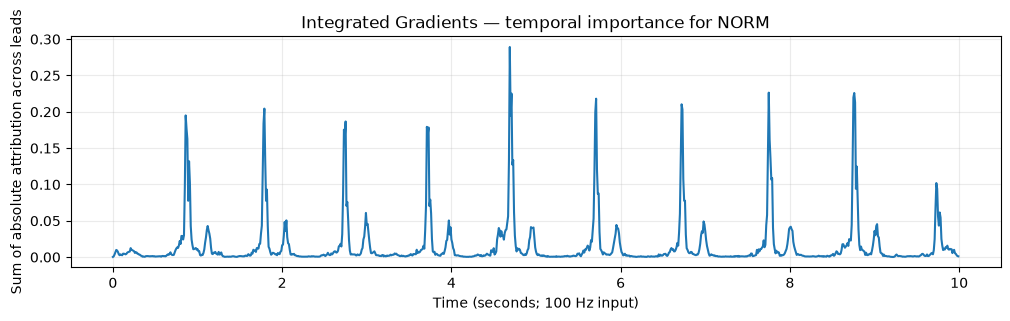

In [4]:
import matplotlib.pyplot as plt

lead_names = list(explanation["lead_importance"].keys())
lead_values = list(explanation["lead_importance"].values())
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(lead_names, lead_values)
ax.set_title(f"Integrated Gradients — lead importance for {label}")
ax.set_ylabel("Sum of absolute attribution")
ax.set_xlabel("ECG lead")
ax.grid(axis="y", alpha=0.25)
plt.show()

time_values = np.asarray(explanation["temporal_importance"], dtype=float)
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(np.arange(len(time_values)) / 100.0, time_values)
ax.set_title(f"Integrated Gradients — temporal importance for {label}")
ax.set_xlabel("Time (seconds; 100 Hz input)")
ax.set_ylabel("Sum of absolute attribution across leads")
ax.grid(alpha=0.25)
plt.show()

## 4. Interpretation limits

- The baseline is a zero waveform; alternative baselines should be evaluated for sensitivity.
- Attribution magnitude indicates model sensitivity relative to the chosen baseline.
- It does not show the causal contribution of an ECG feature or localize an anatomical lesion.
- Report explanation stability across several records and seeds, not only one selected trace.
- PTB-XL labels are dataset annotations; they are not a replacement for a clinician's ECG interpretation.